# ***Importing Libraries***

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

SEED = 42
keras.utils.set_random_seed(SEED)

# ***Exploratory Data Analysis (EDA)***

In [35]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [36]:
df.tail()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [37]:
df.shape

(20640, 9)

In [38]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [39]:
df.dtypes

,0
MedInc,float64
HouseAge,float64
AveRooms,float64
AveBedrms,float64
Population,float64
AveOccup,float64
Latitude,float64
Longitude,float64
MedHouseVal,float64


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [41]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [42]:
df.duplicated().sum()

np.int64(0)

In [43]:
df.isnull().sum() / df.shape[0] * 100

,0
MedInc,0.0
HouseAge,0.0
AveRooms,0.0
AveBedrms,0.0
Population,0.0
AveOccup,0.0
Latitude,0.0
Longitude,0.0
MedHouseVal,0.0


In [44]:
(df['MedHouseVal'] == df['MedHouseVal'].max()).sum()

np.int64(965)

In [45]:
df[['AveRooms', 'AveBedrms', 'AveOccup']].max()

,0
AveRooms,141.909091
AveBedrms,34.066667
AveOccup,1243.333333


# ***Data Visualization***

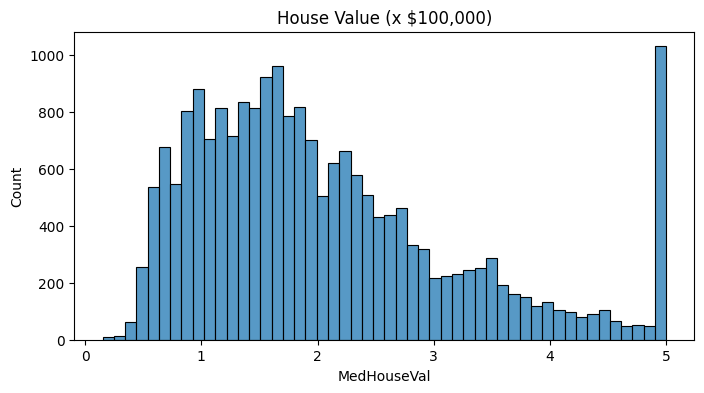

In [46]:
plt.figure(figsize=(8, 4))
sns.histplot(df['MedHouseVal'], bins=50)
plt.title('House Value (x $100,000)')
plt.show()

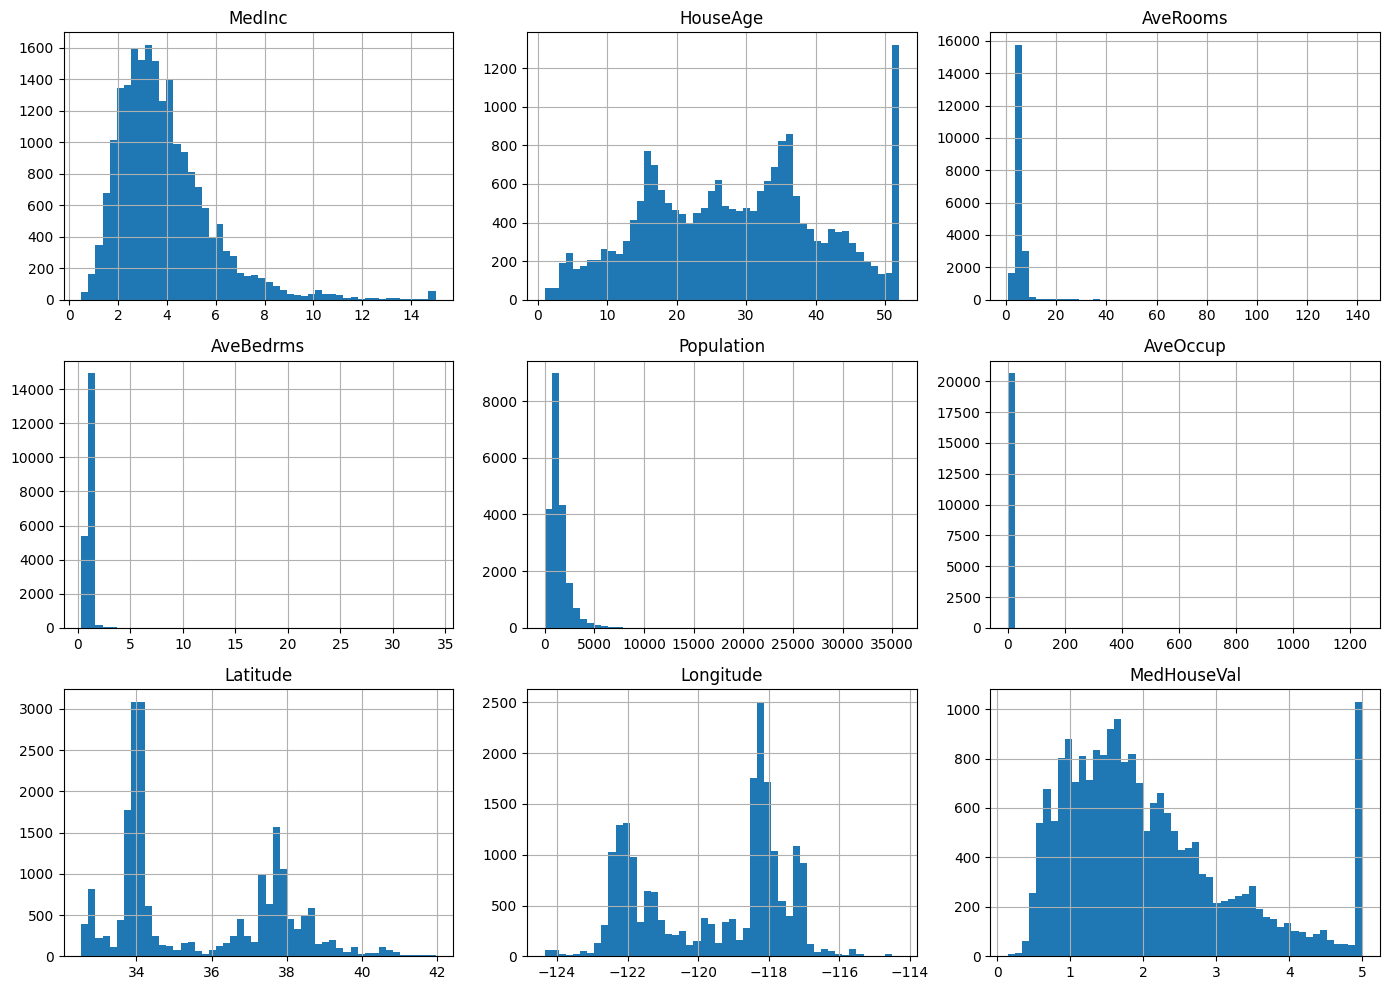

In [47]:
df.hist(bins=50, figsize=(14, 10))
plt.tight_layout()
plt.show()

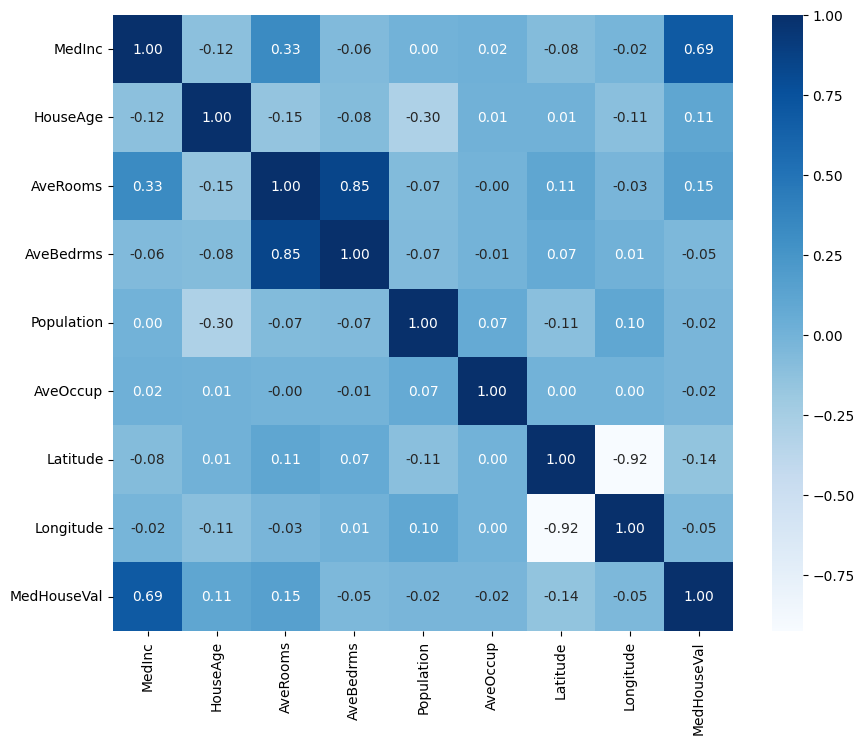

In [48]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='Blues')
plt.show()

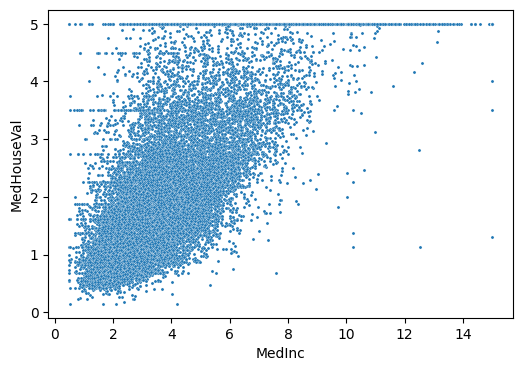

In [49]:
plt.figure(figsize=(6, 4))
sns.scatterplot(x='MedInc', y='MedHouseVal', data=df, s=5)
plt.show()

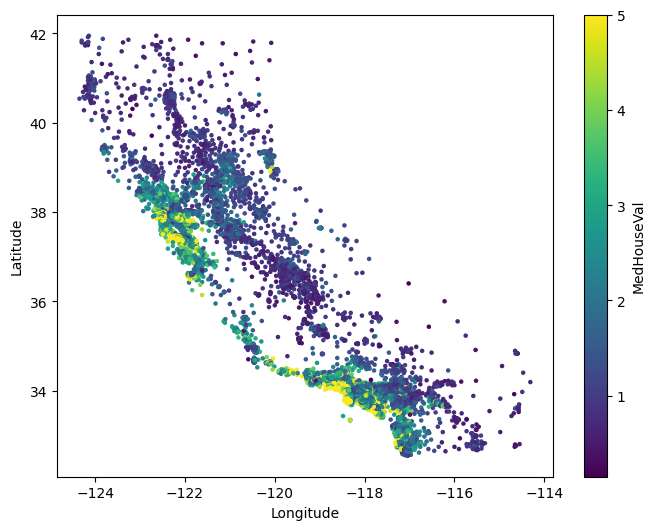

In [50]:
plt.figure(figsize=(8, 6))
plt.scatter(df['Longitude'], df['Latitude'], c=df['MedHouseVal'], cmap='viridis', s=5)
plt.colorbar(label='MedHouseVal')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

# ***Data Preprocessing***

In [51]:
df = df[df['MedHouseVal'] < df['MedHouseVal'].max()]
df = df[(df['AveRooms'] < 20) & (df['AveBedrms'] < 5) & (df['AveOccup'] < 10)]
df.shape

(19572, 9)

In [52]:
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

In [53]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)
print(X_train.shape, X_val.shape, X_test.shape)

(13700, 8) (2936, 8) (2936, 8)


In [54]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# ***Machine Learning Models***

In [55]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

In [56]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

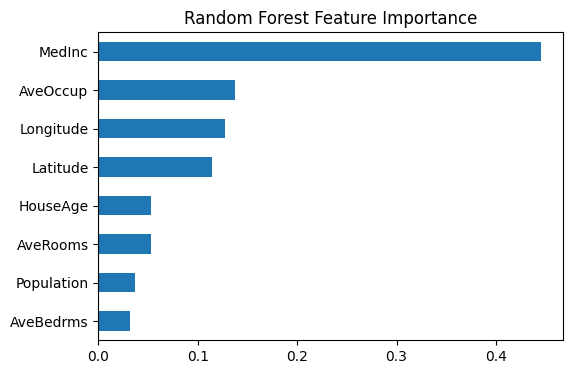

In [57]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh', figsize=(6, 4))
plt.title('Random Forest Feature Importance')
plt.show()

# ***ANN Model***

In [58]:
ann_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1)
])

ann_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
ann_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

In [59]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = ann_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=64, callbacks=[early_stop], verbose=2)

Epoch 1/100
215/215 - 3s - 15ms/step - loss: 0.9266 - mae: 0.6765 - val_loss: 0.3802 - val_mae: 0.4553
Epoch 2/100
215/215 - 1s - 3ms/step - loss: 0.3363 - mae: 0.4201 - val_loss: 0.3136 - val_mae: 0.4125
Epoch 3/100
215/215 - 1s - 3ms/step - loss: 0.2989 - mae: 0.3954 - val_loss: 0.2925 - val_mae: 0.3966
Epoch 4/100
215/215 - 1s - 3ms/step - loss: 0.2857 - mae: 0.3849 - val_loss: 0.2805 - val_mae: 0.3872
Epoch 5/100
215/215 - 1s - 3ms/step - loss: 0.2768 - mae: 0.3773 - val_loss: 0.2726 - val_mae: 0.3805
Epoch 6/100
215/215 - 1s - 3ms/step - loss: 0.2702 - mae: 0.3718 - val_loss: 0.2667 - val_mae: 0.3758
Epoch 7/100
215/215 - 1s - 3ms/step - loss: 0.2645 - mae: 0.3671 - val_loss: 0.2618 - val_mae: 0.3713
Epoch 8/100
215/215 - 1s - 3ms/step - loss: 0.2592 - mae: 0.3629 - val_loss: 0.2575 - val_mae: 0.3688
Epoch 9/100
215/215 - 1s - 4ms/step - loss: 0.2550 - mae: 0.3594 - val_loss: 0.2537 - val_mae: 0.3649
Epoch 10/100
215/215 - 1s - 6ms/step - loss: 0.2510 - mae: 0.3562 - val_loss: 0.2

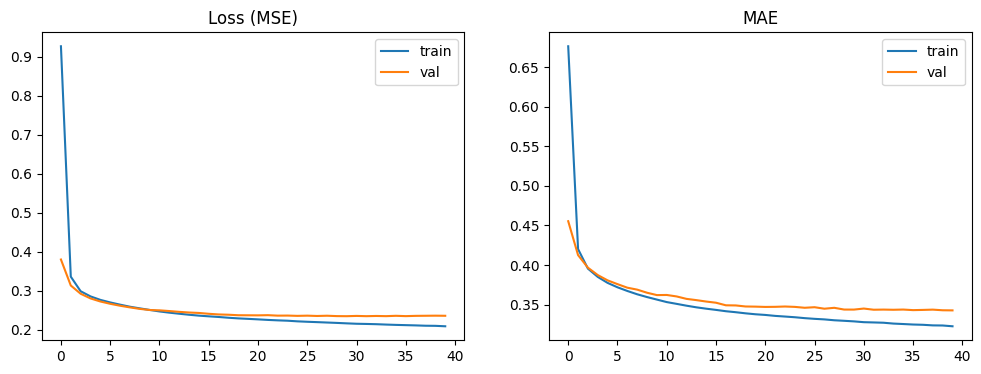

In [60]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title('Loss (MSE)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='train')
plt.plot(history.history['val_mae'], label='val')
plt.title('MAE')
plt.legend()

plt.show()

# ***Evaluating the ANN***

In [61]:
y_pred_ann = ann_model.predict(X_test, verbose=0).ravel()

print("MAE:", mean_absolute_error(y_test, y_pred_ann))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ann)))
print("R2:", r2_score(y_test, y_pred_ann))

MAE: 0.33646507327713987
RMSE: 0.4778478521472906
R2: 0.7555191536118797


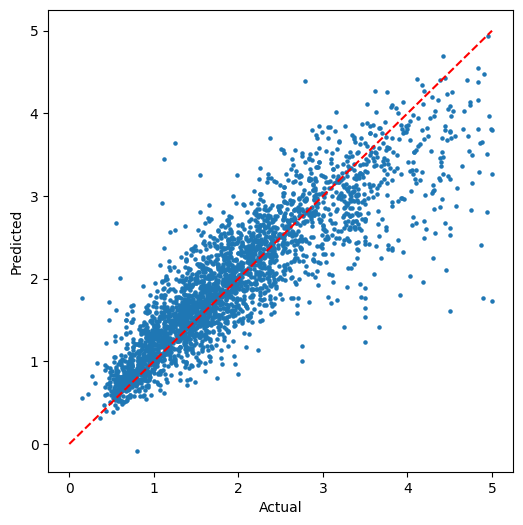

In [62]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_ann, s=5)
plt.plot([0, 5], [0, 5], 'r--')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

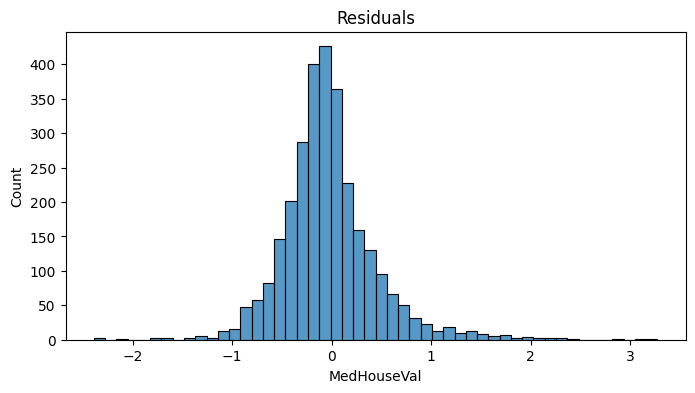

In [63]:
residuals = y_test - y_pred_ann

plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=50)
plt.title('Residuals')
plt.show()

# ***Model Comparison***

In [64]:
results = []
for name, y_pred in [("Linear Regression", y_pred_lr), ("Random Forest", y_pred_rf), ("ANN", y_pred_ann)]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="RMSE")
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,MAE,RMSE,R2
0,Random Forest,0.299091,0.450545,0.782659
1,ANN,0.336465,0.477848,0.755519
2,Linear Regression,0.428892,0.583841,0.635033


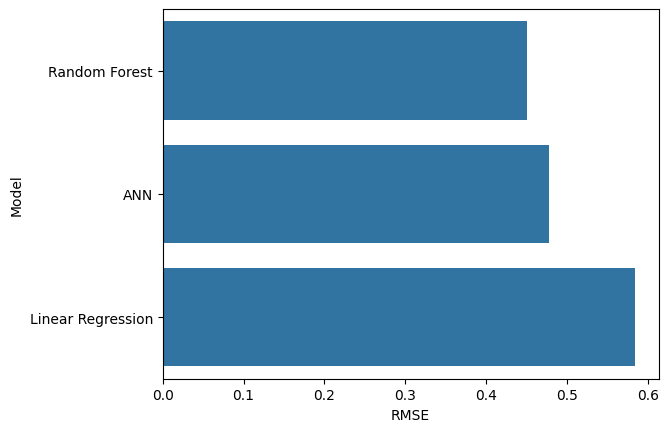

In [65]:
sns.barplot(x="RMSE", y="Model", data=results_df)
plt.show()